In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/javeriaismail99/flicker-data/captions.txt


In [7]:
import pandas as pd

captions_path = "/kaggle/input/datasets/javeriaismail99/flicker-data/captions.txt"

captions_df = pd.read_csv(captions_path)

sample_captions = captions_df["caption"].drop_duplicates().sample(
    3,
    random_state=42
).tolist()

for c in sample_captions:
    print(c)

A girl plays T-ball .
A woman in riding attire rides a jumping horse .
A brown dog wearing a pink shirt is followed by a brown dog wearing a yellow shirt .


In [8]:
!pip install -q diffusers transformers accelerate safetensors


In [9]:
from diffusers import StableDiffusionPipeline
import torch

pipe = StableDiffusionPipeline.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

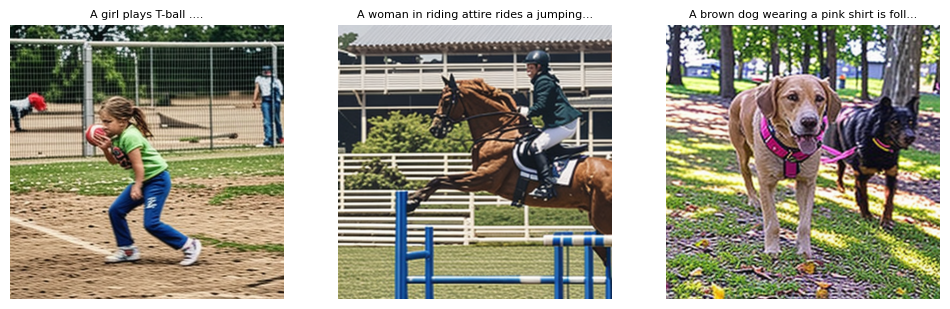

In [10]:
import matplotlib.pyplot as plt

images = [
    pipe(
        prompt=c,
        num_inference_steps=4,
        guidance_scale=0.0
    ).images[0]
    for c in sample_captions
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, (img, cap) in enumerate(zip(images, sample_captions)):
    axes[i].imshow(img)
    axes[i].set_title(cap[:40] + "...", fontsize=8)
    axes[i].axis("off")

plt.show()


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

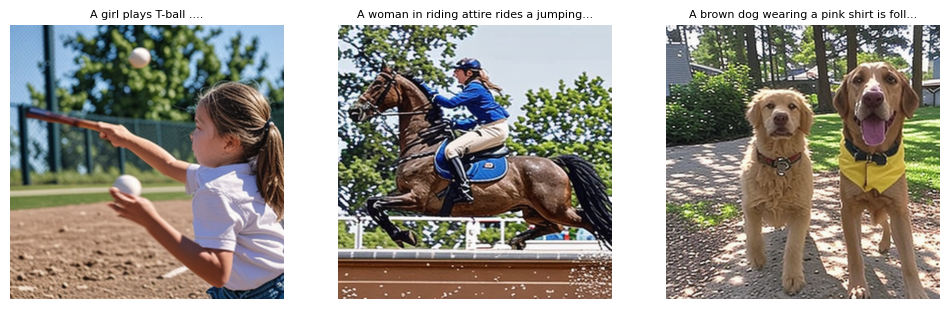

In [11]:
import matplotlib.pyplot as plt

images = [
    pipe(
        prompt=c,
        num_inference_steps=4,
        guidance_scale=0.0
    ).images[0]
    for c in sample_captions
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, (img, cap) in enumerate(zip(images, sample_captions)):
    axes[i].imshow(img)
    axes[i].set_title(cap[:40] + "...", fontsize=8)
    axes[i].axis("off")

plt.show()

In [12]:
import torch
from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"

pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

pipe = pipe.to(device)

print("Using:", device)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Using: cuda


  0%|          | 0/50 [00:00<?, ?it/s]

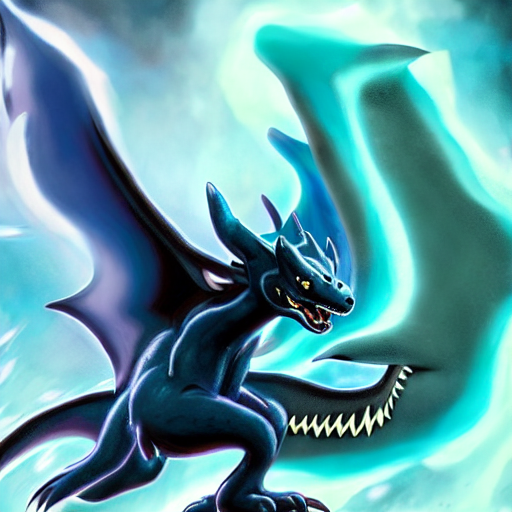

In [13]:
caption ="Toothless the Night Fury dragon breathing a huge blue plasma blast from his mouth, massive stream of blue fire, glowing energy flames, sparks and smoke, mouth wide open, flying through the clouds, black scales, green eyes, cinematic action scene, dramatic lighting, ultra detailed, masterpiece, 4k"

image = pipe(caption).images[0]

display(image)

In [14]:
image.save("toothless_fire.png")
print("Saved!")

Saved!


In [15]:
import os
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'toothless_fire.png']
